# Task B — Evaluation: Load Checkpoints & Extract Metrics

**Mục đích:** Đánh giá 15 lần chạy (5 backbones × 3 seeds) đã train trên Vast.ai bằng cách:
1. **Parse log từ notebook cell outputs** → trích xuất lịch sử train/val theo từng epoch
2. **Load checkpoint .pth** → tính Test metrics (Accuracy, Precision, Recall, F1-macro, per-class F1)

**Môi trường chạy:** Vast.ai (SSH), path gốc `/workspace/woodbench`  
**Dữ liệu:** `data/task-B` (flat structure, đã download từ HuggingFace `ny0g507h3p/wood-task-B`)  
**Checkpoints:** `data/experiments/taskB/<backbone>/seed_<N>/`  

---
## Cấu hình đã dùng khi train (đọc từ notebooks)

| Backbone | Batch | LR head | LR backbone | Label Smooth | Scheduler | Epochs | Early Stop |
|---|---|---|---|---|---|---|---|
| resnet50 | 64 | 1e-4 | 1e-5 | 0.1 | cosine | 50 | patience=10 |
| convnext_tiny | 32 | 1e-4 | 1e-5 | 0.1 | cosine | 50 | patience=10 |
| efficientnet_b3 | 32 | 1e-4 | 1e-5 | 0.1 | cosine | 50 | patience=10 |
| mobilenetv3_large | 64 | 1e-4 | 1e-5 | 0.1 | cosine | 50 | patience=10 |
| swin_tiny | 32 | 1e-4 | 1e-5 | 0.1 | cosine | 50 | patience=10 |

**Seeds:** 42, 123, 456 | **WandB project:** `woodbench-taskB`  
**Dataset split:** Train=3973, Val=933, Test=924 | **Classes:** 20 species

In [2]:
# ============================================================================
# Cell 1 — Root Detection (KHÔNG THAY ĐỔI)
# ============================================================================
from pathlib import Path
import sys, os

if Path('/content').exists():
    ROOT = Path('/content/woodbench')
else:
    ROOT = Path.cwd()
    for parent in [ROOT] + list(ROOT.parents):
        if (parent / 'train.py').exists() or (parent / 'pyproject.toml').exists():
            ROOT = parent
            break

sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
print(f'ROOT: {ROOT}')

ROOT: /home/sakana/Code/ManifoldsTeam/woodbench


In [3]:
# ============================================================================
# Cell 2 — Imports
# ============================================================================
import json
import re
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.metrics import classification_report
from torch.utils.data import DataLoader

from src.models import create_model
from src.data import get_val_transforms
from src.data.dataset import _detect_structure, FlatConiferDataset, ConiferDataset
from src.eval.metrics import compute_metrics

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')

/home/sakana/miniconda3/envs/wood/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


In [4]:
# ============================================================================
# Cell 3 — CẤU HÌNH (chỉnh tại đây nếu cần)
# ============================================================================

# Thư mục data (flat structure: data/task-B/train/<species>/)
DATA_ROOT = ROOT / 'data' / 'task-B'

# Thư mục chứa checkpoints (tìm đệ quy theo pattern *_best.pth)
CHECKPOINTS_DIR = ROOT / 'data' / 'experiments' / 'taskB'

# Thư mục notebook nguồn (để parse log)
NOTEBOOKS_DIR = ROOT / 'notebooks' / 'phase 1' / 'task-B'

# Thư mục lưu kết quả tổng hợp
OUTPUT_DIR = ROOT / 'data' / 'experiments' / 'taskB' / '_evaluation'

# Task config
TASK_ID     = 'taskB'
NUM_CLASSES = 20
IMG_SIZE    = 224
BATCH_SIZE  = 64
NUM_WORKERS = 4

# Mapping tên backbone (dùng để suy ra từ tên thư mục/file)
BACKBONE_MAP = {
    'resnet50':          'resnet50',
    'convnext_tiny':     'convnext_tiny',
    'efficientnet_b3':   'efficientnet_b3',
    'mobilenetv3_large': 'mobilenetv3_large',
    'swin_tiny':         'swin_tiny',
}

# Seeds đã dùng (theo thứ tự)
SEEDS = [42, 123, 456]

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f'DATA_ROOT       : {DATA_ROOT}')
print(f'CHECKPOINTS_DIR : {CHECKPOINTS_DIR}')
print(f'NOTEBOOKS_DIR   : {NOTEBOOKS_DIR}')
print(f'OUTPUT_DIR      : {OUTPUT_DIR}')

DATA_ROOT       : /home/sakana/Code/ManifoldsTeam/woodbench/data/task-B
CHECKPOINTS_DIR : /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/taskB
NOTEBOOKS_DIR   : /home/sakana/Code/ManifoldsTeam/woodbench/notebooks/phase 1/task-B
OUTPUT_DIR      : /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/taskB/_evaluation


In [5]:
# ============================================================================
# Cell 4 — Hàm Parse Log từ Notebook (.ipynb cell outputs)
# ============================================================================

EPOCH_RE = re.compile(
    r'Epoch\s+(\d+)/\d+\s*\|\s*'
    r'Train Loss:\s*([\d.]+),\s*Acc:\s*([\d.]+)%\s*\|\s*'
    r'Val Loss:\s*([\d.]+),\s*Acc:\s*([\d.]+)%\s*\|\s*'
    r'LR:\s*([\d.e+\-]+)'
)

SEED_HEADER_RE = re.compile(
    r'seed[=]?(\d+)',
    re.IGNORECASE
)

BEST_VAL_RE = re.compile(
    r'\[(\w+)\s+s(\d+)\]\s+val_acc=([\d.]+)%'
)


def _extract_text_from_outputs(cell_outputs: list) -> str:
    """Ghép tất cả text (stdout + stderr) trong outputs của một cell."""
    lines = []
    for output in cell_outputs:
        if output.get('output_type') in ('stream',):
            lines.extend(output.get('text', []))
    return ''.join(lines)


def parse_notebook_logs(notebook_path: Path) -> dict:
    """
    Parse toàn bộ lịch sử train/val epoch-by-epoch từ cell outputs của notebook.

    Returns:
        dict: {
            backbone: str,
            runs: [
                {
                    seed: int,
                    best_val_acc: float,  # (%) từ summary cuối seed
                    history: [
                        {epoch, train_loss, train_acc, val_loss, val_acc, lr, is_best},
                        ...
                    ]
                },
                ...
            ]
        }
    """
    with open(notebook_path, 'r', encoding='utf-8') as f:
        nb = json.load(f)

    # Suy ra backbone từ tên notebook
    stem = notebook_path.stem  # e.g. 'TaskB_resnet50'
    backbone = None
    for key in BACKBONE_MAP:
        if key in stem:
            backbone = BACKBONE_MAP[key]
            break
    if backbone is None:
        print(f'  ⚠️  Không xác định backbone từ tên file: {stem}')
        return {}

    # Ghép toàn bộ text output của tất cả cells
    all_text = ''
    for cell in nb.get('cells', []):
        if cell.get('cell_type') == 'code':
            all_text += _extract_text_from_outputs(cell.get('outputs', []))

    # Chia thành blocks theo seed (mỗi seed bắt đầu bằng section header)
    # Strategy: split theo "[backbone s<seed>] train=..."
    seed_split_re = re.compile(
        rf'\[{re.escape(backbone)}\s+s(\d+)\]\s+train='
    )
    blocks = seed_split_re.split(all_text)
    # blocks[0] = phần trước seed đầu tiên
    # blocks[1] = seed number, blocks[2] = nội dung seed đó
    # blocks[3] = seed number, blocks[4] = nội dung...

    runs = []
    i = 1
    while i + 1 < len(blocks):
        seed = int(blocks[i])
        block_text = blocks[i + 1]

        # Parse từng epoch
        history = []
        for m in EPOCH_RE.finditer(block_text):
            epoch      = int(m.group(1))
            train_loss = float(m.group(2))
            train_acc  = float(m.group(3))
            val_loss   = float(m.group(4))
            val_acc    = float(m.group(5))
            lr         = float(m.group(6))
            # Xác định best epoch
            after_match = block_text[m.end():m.end() + 100]
            is_best = '[Best]' in block_text[m.start():m.end() + 10]
            history.append({
                'epoch':      epoch,
                'train_loss': train_loss,
                'train_acc':  train_acc,
                'val_loss':   val_loss,
                'val_acc':    val_acc,
                'lr':         lr,
                'is_best':    is_best,
            })

        # Tìm best_val_acc từ dòng summary "[backbone sN] val_acc=X%"
        summary_re = re.compile(
            rf'\[{re.escape(backbone)}\s+s{seed}\]\s+val_acc=([\d.]+)%'
        )
        sm = summary_re.search(block_text)
        best_val_acc = float(sm.group(1)) if sm else (
            max(h['val_acc'] for h in history) if history else None
        )

        epochs_trained = len(history)
        early_stopped  = epochs_trained < 50

        if history:
            runs.append({
                'seed':          seed,
                'best_val_acc':  best_val_acc,
                'epochs_trained': epochs_trained,
                'early_stopped': early_stopped,
                'history':       history,
            })
        i += 2

    return {'backbone': backbone, 'runs': runs}


print('Hàm parse_notebook_logs() sẵn sàng.')

Hàm parse_notebook_logs() sẵn sàng.


In [6]:
# ============================================================================
# Cell 5 — Parse log từ tất cả notebook và lưu history
# ============================================================================

NOTEBOOK_FILES = sorted(NOTEBOOKS_DIR.glob('TaskB_*.ipynb'))
# Bỏ notebook eval (chính notebook này)
NOTEBOOK_FILES = [f for f in NOTEBOOK_FILES if 'Evaluate' not in f.stem]

print(f'Tìm thấy {len(NOTEBOOK_FILES)} notebook training:\n')
for nb_path in NOTEBOOK_FILES:
    print(f'  {nb_path.name}')

all_log_data = {}   # backbone -> parsed log dict

for nb_path in NOTEBOOK_FILES:
    print(f'\nParsing: {nb_path.name} ...', end=' ')
    result = parse_notebook_logs(nb_path)
    if not result:
        print('SKIP (không tìm thấy backbone)')
        continue

    backbone = result['backbone']
    runs     = result['runs']
    all_log_data[backbone] = result

    print(f'backbone={backbone}, {len(runs)} seeds tìm thấy')
    for r in runs:
        hist = r['history']
        print(
            f"  seed={r['seed']:>3} | epochs_trained={r['epochs_trained']:>2} | "
            f"best_val_acc={r['best_val_acc']:.2f}% | early_stopped={r['early_stopped']}"
        )
        if hist:
            best = max(hist, key=lambda h: h['val_acc'])
            last = hist[-1]
            print(
                f"    best epoch={best['epoch']} val_acc={best['val_acc']:.2f}%  "
                f"| last epoch train_acc={last['train_acc']:.2f}%"
            )

    # Lưu history ra JSON cho từng seed
    for r in runs:
        seed_dir = CHECKPOINTS_DIR / backbone / f"seed_{r['seed']}"
        seed_dir.mkdir(parents=True, exist_ok=True)
        hist_path = seed_dir / 'train_history.json'
        with open(hist_path, 'w') as fp:
            json.dump({
                'backbone':       backbone,
                'seed':           r['seed'],
                'best_val_acc':   r['best_val_acc'],
                'epochs_trained': r['epochs_trained'],
                'early_stopped':  r['early_stopped'],
                'history':        r['history'],
            }, fp, indent=2)
        print(f'    → Saved history: {hist_path.relative_to(ROOT)}')

print(f'\n✅ Parse xong {len(all_log_data)} backbone(s).')

Tìm thấy 6 notebook training:

  TaskB_Results_Driver.ipynb
  TaskB_convnext_tiny.ipynb
  TaskB_efficientnet_b3.ipynb
  TaskB_mobilenetv3_large.ipynb
  TaskB_resnet50.ipynb
  TaskB_swin_tiny.ipynb

Parsing: TaskB_Results_Driver.ipynb ...   ⚠️  Không xác định backbone từ tên file: TaskB_Results_Driver
SKIP (không tìm thấy backbone)

Parsing: TaskB_convnext_tiny.ipynb ... backbone=convnext_tiny, 3 seeds tìm thấy
  seed= 42 | epochs_trained=23 | best_val_acc=100.00% | early_stopped=True
    best epoch=13 val_acc=100.00%  | last epoch train_acc=99.77%
  seed=123 | epochs_trained=25 | best_val_acc=100.00% | early_stopped=True
    best epoch=15 val_acc=100.00%  | last epoch train_acc=100.00%
  seed=456 | epochs_trained=20 | best_val_acc=100.00% | early_stopped=True
    best epoch=10 val_acc=100.00%  | last epoch train_acc=99.97%
    → Saved history: data/experiments/taskB/convnext_tiny/seed_42/train_history.json
    → Saved history: data/experiments/taskB/convnext_tiny/seed_123/train_history

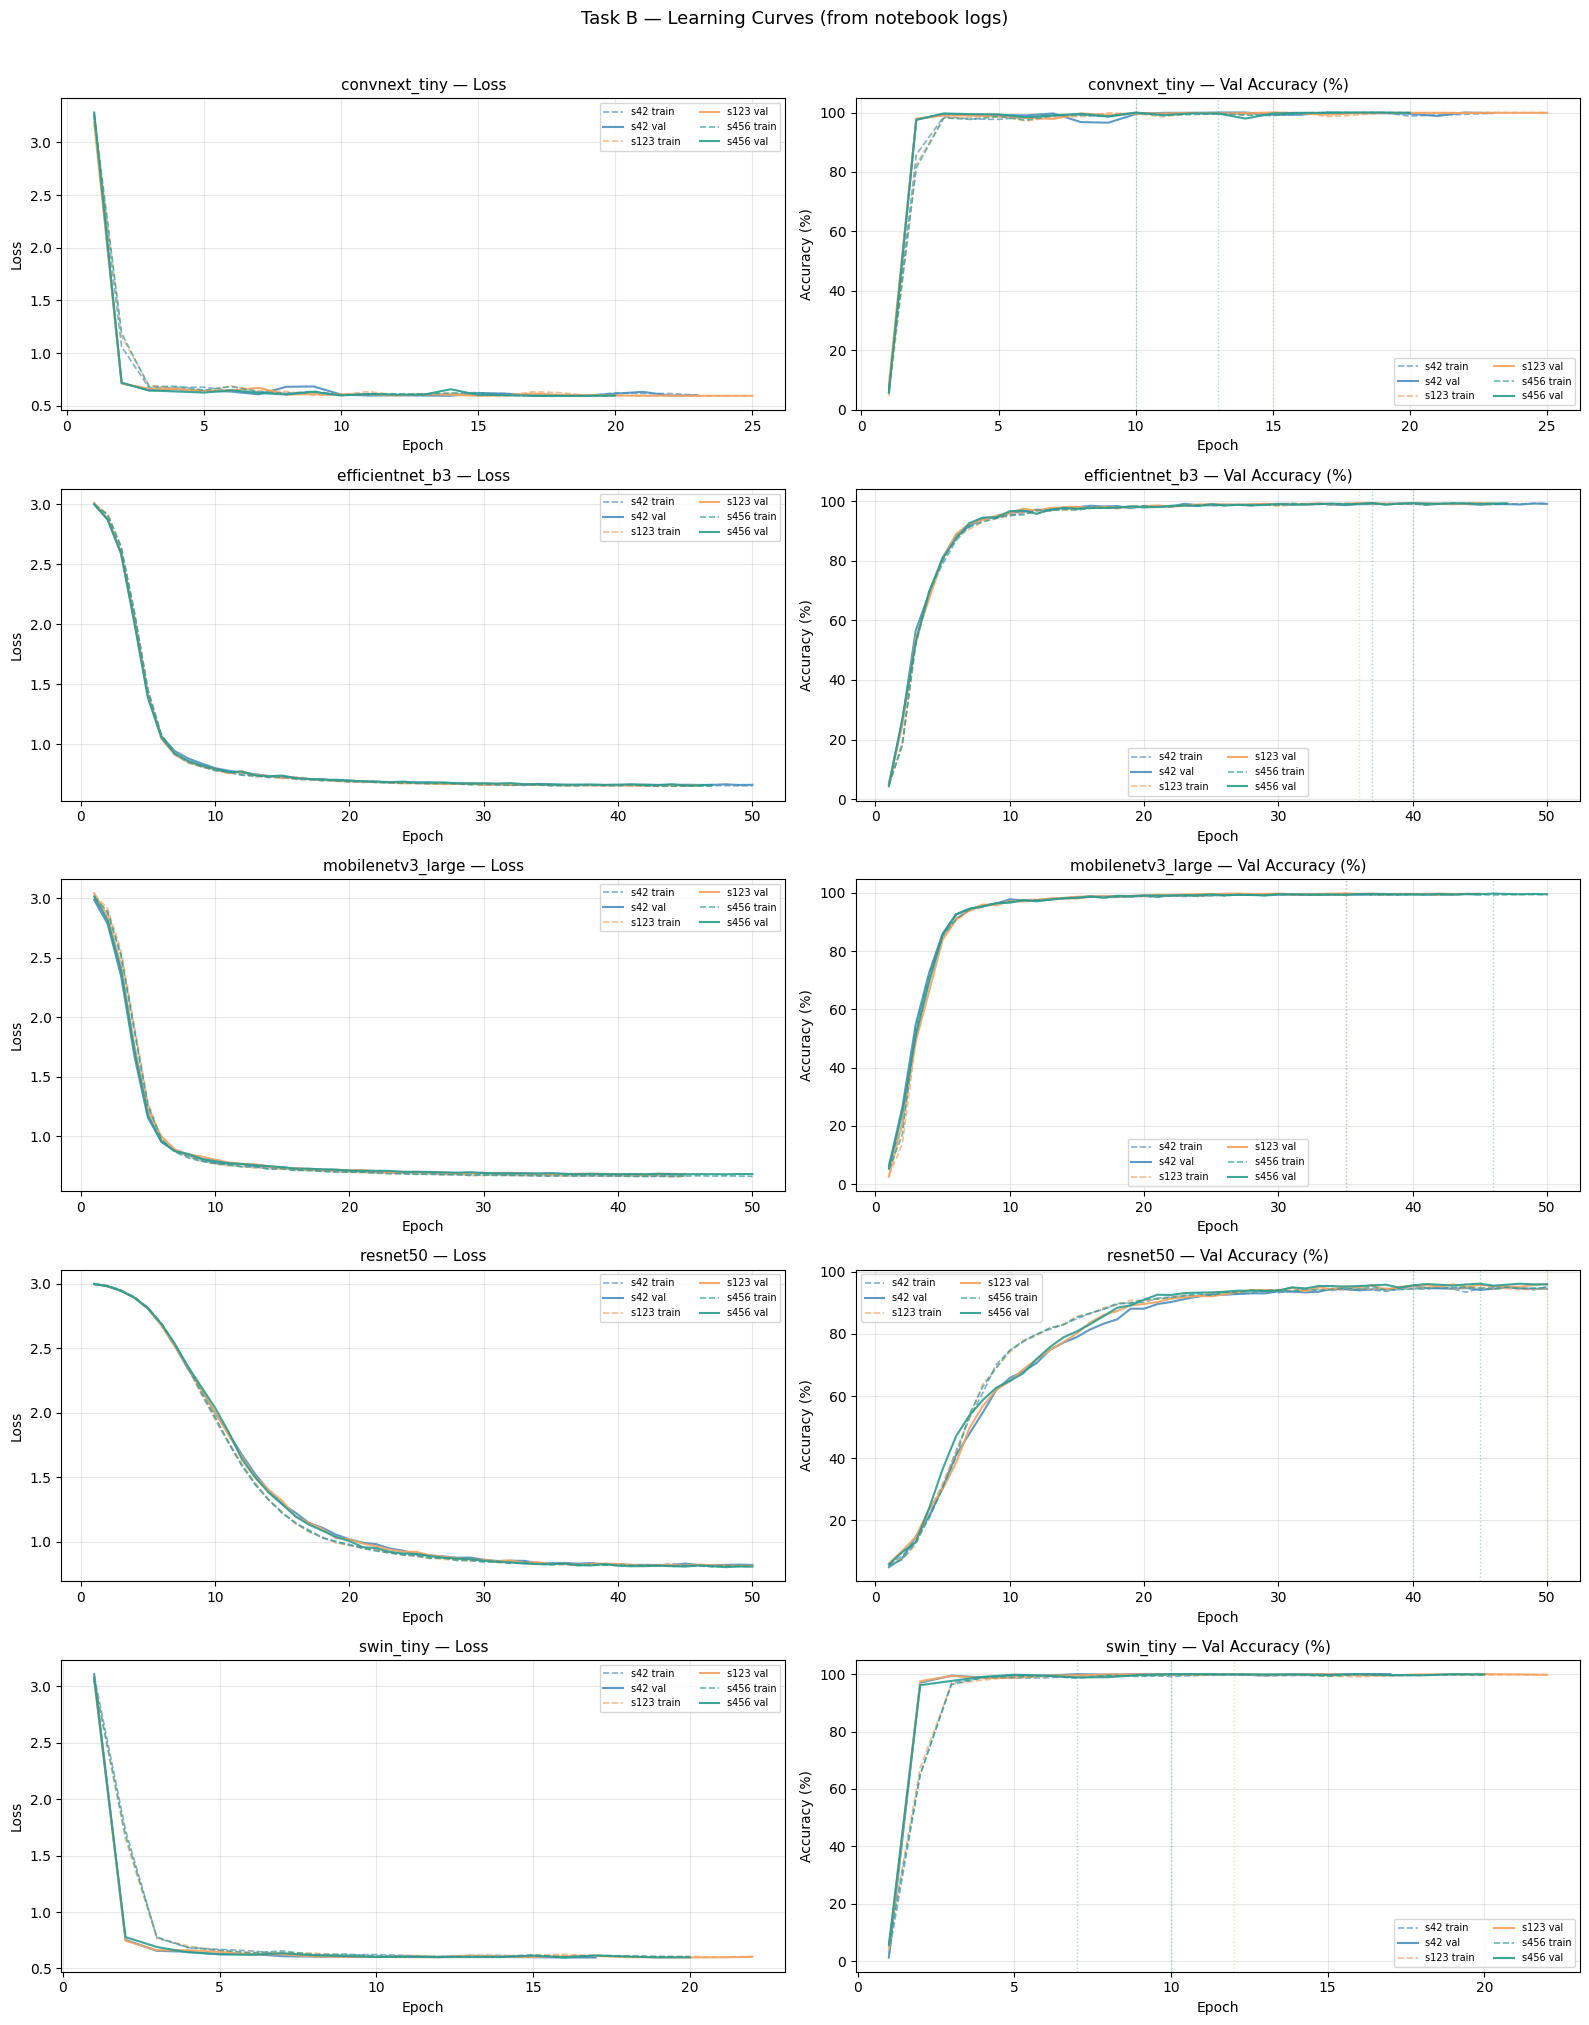

Đã lưu: /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/taskB/_evaluation/learning_curves_all_backbones.png


In [7]:
# ============================================================================
# Cell 6 — Vẽ Learning Curves từ log đã parse
# ============================================================================

if not all_log_data:
    print('Không có log để vẽ.')
else:
    n_backbones = len(all_log_data)
    fig, axes = plt.subplots(n_backbones, 2, figsize=(16, 4 * n_backbones))
    if n_backbones == 1:
        axes = [axes]  # wrap để indexing nhất quán

    SEED_COLORS = {42: '#4C8FBF', 123: '#F4A261', 456: '#2A9D8F'}

    for row_idx, (backbone, log) in enumerate(sorted(all_log_data.items())):
        ax_loss, ax_acc = axes[row_idx]

        for run in log['runs']:
            seed    = run['seed']
            history = run['history']
            if not history:
                continue
            epochs_x   = [h['epoch'] for h in history]
            train_loss = [h['train_loss'] for h in history]
            val_loss   = [h['val_loss'] for h in history]
            train_acc  = [h['train_acc'] for h in history]
            val_acc    = [h['val_acc'] for h in history]
            color      = SEED_COLORS.get(seed, '#888')

            ax_loss.plot(epochs_x, train_loss, color=color, linestyle='--', alpha=0.7,
                         linewidth=1.2, label=f's{seed} train')
            ax_loss.plot(epochs_x, val_loss, color=color, linestyle='-', alpha=0.9,
                         linewidth=1.5, label=f's{seed} val')

            ax_acc.plot(epochs_x, train_acc, color=color, linestyle='--', alpha=0.7,
                        linewidth=1.2, label=f's{seed} train')
            ax_acc.plot(epochs_x, val_acc, color=color, linestyle='-', alpha=0.9,
                        linewidth=1.5, label=f's{seed} val')

            # Mark best epoch
            best_h = max(history, key=lambda h: h['val_acc'])
            ax_acc.axvline(x=best_h['epoch'], color=color, linestyle=':', alpha=0.4, linewidth=1)

        ax_loss.set_title(f'{backbone} — Loss', fontsize=11)
        ax_loss.set_xlabel('Epoch'); ax_loss.set_ylabel('Loss')
        ax_loss.legend(fontsize=7, ncol=2); ax_loss.grid(alpha=0.3)

        ax_acc.set_title(f'{backbone} — Val Accuracy (%)', fontsize=11)
        ax_acc.set_xlabel('Epoch'); ax_acc.set_ylabel('Accuracy (%)')
        ax_acc.legend(fontsize=7, ncol=2); ax_acc.grid(alpha=0.3)

    plt.suptitle('Task B — Learning Curves (from notebook logs)', fontsize=13, y=1.01)
    plt.tight_layout()
    lc_path = OUTPUT_DIR / 'learning_curves_all_backbones.png'
    fig.savefig(lc_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Đã lưu: {lc_path}')

In [8]:
# ============================================================================
# Cell 7 — Hàm tiện ích cho Evaluation
# ============================================================================

def _infer_backbone(checkpoint_path: Path) -> str:
    """Suy ra backbone từ metadata .pth hoặc từ tên thư mục/file."""
    ckpt = torch.load(checkpoint_path, map_location='cpu')
    config = ckpt.get('config', {})
    if 'backbone' in config:
        return config['backbone']
    model_cfg = config.get('model', {})
    if 'backbone' in model_cfg:
        return model_cfg['backbone']
    for part in reversed(checkpoint_path.parts):
        for key in BACKBONE_MAP:
            if key in part:
                return BACKBONE_MAP[key]
    for key in BACKBONE_MAP:
        if key in checkpoint_path.stem:
            return BACKBONE_MAP[key]
    raise ValueError(f'Không xác định được backbone: {checkpoint_path}')


def _infer_seed(checkpoint_path: Path) -> int:
    for part in reversed(checkpoint_path.parts):
        m = re.search(r'seed[_\-]?(\d+)', part, re.IGNORECASE)
        if m:
            return int(m.group(1))
    m = re.search(r'seed[_\-]?(\d+)', checkpoint_path.stem, re.IGNORECASE)
    return int(m.group(1)) if m else -1


def find_checkpoints(base_dir: Path) -> list:
    candidates = []
    for pattern in ['*_best.pth', 'best.pth', '*best*.pth']:
        candidates.extend(base_dir.rglob(pattern))
    return sorted(set(candidates))


def build_test_loader(data_root: Path, img_size: int, batch_size: int, num_workers: int):
    val_transform = get_val_transforms(img_size=img_size)
    structure  = _detect_structure(data_root, 'test')
    DatasetCls = FlatConiferDataset if structure == 'flat' else ConiferDataset
    test_ds    = DatasetCls(data_root, split='test', transform=val_transform, task='taskB')
    assert len(test_ds) > 0, f'Không tìm thấy ảnh trong {data_root}/test'
    loader = DataLoader(
        test_ds, batch_size=batch_size, shuffle=False,
        num_workers=num_workers, pin_memory=(DEVICE == 'cuda'),
        persistent_workers=(num_workers > 0),
        prefetch_factor=2 if num_workers > 0 else None,
    )
    return loader


def load_model_from_checkpoint(checkpoint_path: Path, backbone: str, num_classes: int, device: str):
    ckpt  = torch.load(checkpoint_path, map_location='cpu')
    model = create_model(backbone_name=backbone, num_classes=num_classes,
                         pretrained=False, freeze_backbone=False)
    model.load_state_dict(ckpt['model_state_dict'])
    model = model.to(device)
    model.eval()
    best_epoch   = ckpt.get('best_epoch', ckpt.get('epoch', -1))
    best_val_acc = ckpt.get('best_val_acc', ckpt.get('metrics', {}).get('val_acc', None))
    return model, best_epoch, best_val_acc


print('Hàm tiện ích eval sẵn sàng.')

Hàm tiện ích eval sẵn sàng.


In [10]:
# ============================================================================
# Cell 8 — Build Test DataLoader (1 lần cho toàn bộ eval)
# ============================================================================

test_loader = build_test_loader(
    data_root=DATA_ROOT,
    img_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
)

CLASS_NAMES = test_loader.dataset.classes
print(f'Test set : {len(test_loader.dataset)} ảnh')
print(f'Classes  : {len(CLASS_NAMES)} ({CLASS_NAMES[:3]}...)')

Test set : 924 ảnh
Classes  : 20 (['Araucaria araucana', 'Callitris columellaris', 'Calocedrus rupestris']...)


In [12]:
# ============================================================================
# Cell 9 — Tìm & Liệt kê checkpoints
# ============================================================================

checkpoints = find_checkpoints(CHECKPOINTS_DIR)

if not checkpoints:
    print(f'⚠️  Không tìm thấy checkpoint nào trong: {CHECKPOINTS_DIR}')
else:
    print(f'Tìm thấy {len(checkpoints)} checkpoint(s):\n')
    for i, ckpt_path in enumerate(checkpoints):
        try:
            backbone = _infer_backbone(ckpt_path)
        except ValueError:
            backbone = '???'
        seed = _infer_seed(ckpt_path)
        print(f'  [{i:2d}] backbone={backbone:<22} seed={seed:<6} | {ckpt_path.relative_to(ROOT)}')

Tìm thấy 15 checkpoint(s):

  [ 0] backbone=convnext_tiny          seed=123    | data/experiments/taskB/convnext_tiny/seed_123/convnext_tiny_seed123_best.pth
  [ 1] backbone=convnext_tiny          seed=42     | data/experiments/taskB/convnext_tiny/seed_42/convnext_tiny_seed42_best.pth
  [ 2] backbone=convnext_tiny          seed=456    | data/experiments/taskB/convnext_tiny/seed_456/convnext_tiny_seed456_best.pth
  [ 3] backbone=efficientnet_b3        seed=123    | data/experiments/taskB/efficientnet_b3/seed_123/efficientnet_b3_seed123_best.pth
  [ 4] backbone=efficientnet_b3        seed=42     | data/experiments/taskB/efficientnet_b3/seed_42/efficientnet_b3_seed42_best.pth
  [ 5] backbone=efficientnet_b3        seed=456    | data/experiments/taskB/efficientnet_b3/seed_456/efficientnet_b3_seed456_best.pth
  [ 6] backbone=mobilenetv3_large      seed=123    | data/experiments/taskB/mobilenetv3_large/seed_123/mobilenetv3_large_seed123_best.pth
  [ 7] backbone=mobilenetv3_large      seed=42

In [ ]:
# ============================================================================
# Cell 10 — Eval vòng lặp chính: Load .pth → tính Test metrics
# ============================================================================

all_results = []  # list of dicts

for i, ckpt_path in enumerate(checkpoints):
    # --- Suy ra backbone & seed ---
    try:
        backbone = _infer_backbone(ckpt_path)
    except ValueError as e:
        print(f'[{i:2d}] SKIP — {e}')
        continue

    seed   = _infer_seed(ckpt_path)
    run_id = f'{backbone}_seed{seed}'
    print(f'[{i:2d}] Evaluating: {run_id} ...', end=' ', flush=True)

    # --- Load model ---
    try:
        model, best_epoch, ckpt_val_acc = load_model_from_checkpoint(
            ckpt_path, backbone, NUM_CLASSES, DEVICE
        )
    except Exception as e:
        print(f'LỖI load model: {e}')
        continue

    # --- Tính Test metrics ---
    try:
        metrics = compute_metrics(
            model=model, data_loader=test_loader,
            device=DEVICE, num_classes=NUM_CLASSES,
            class_names=CLASS_NAMES,
        )
    except Exception as e:
        print(f'LỖI compute metrics: {e}')
        continue

    acc  = metrics['accuracy']
    prec = metrics['precision_macro']
    rec  = metrics['recall_macro']
    f1   = metrics['f1_macro']
    print(f'Acc={acc*100:.2f}%  F1={f1*100:.2f}%')

    # --- Lấy thông tin từ log đã parse (nếu có) ---
    log_run = None
    if backbone in all_log_data:
        for lr in all_log_data[backbone]['runs']:
            if lr['seed'] == seed:
                log_run = lr
                break

    best_val_acc_log  = log_run['best_val_acc']  if log_run else None
    epochs_trained    = log_run['epochs_trained'] if log_run else None
    early_stopped     = log_run['early_stopped']  if log_run else None

    # --- Lưu test_metrics.json cạnh checkpoint ---
    run_output_dir = ckpt_path.parent
    metrics_to_save = {
        'run_id':          run_id,
        'backbone':        backbone,
        'seed':            seed,
        # Train info (từ checkpoint)
        'best_epoch':      int(best_epoch) if best_epoch is not None else None,
        'best_val_acc_ckpt': float(ckpt_val_acc) if ckpt_val_acc is not None else None,
        # Train info (từ notebook log)
        'best_val_acc_log': float(best_val_acc_log) if best_val_acc_log is not None else None,
        'epochs_trained':  epochs_trained,
        'early_stopped':   early_stopped,
        # Test metrics
        'accuracy':        float(acc),
        'precision_macro': float(prec),
        'recall_macro':    float(rec),
        'f1_macro':        float(f1),
        'per_class_f1': {
            cls: float(scores['f1'])
            for cls, scores in metrics['per_class'].items()
        },
        'per_class_precision': {
            cls: float(scores['precision'])
            for cls, scores in metrics['per_class'].items()
        },
        'per_class_recall': {
            cls: float(scores['recall'])
            for cls, scores in metrics['per_class'].items()
        },
    }
    with open(run_output_dir / 'test_metrics.json', 'w') as fp:
        json.dump(metrics_to_save, fp, indent=2)

    all_results.append({
        **metrics_to_save,
        'checkpoint': str(ckpt_path),
        '_metrics':   metrics,  # raw metrics object cho plot sau
    })

    del model
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()

print(f'\n Hoàn thành: {len(all_results)}/{len(checkpoints)} checkpoints.')

[ 0] Evaluating: convnext_tiny_seed123 ... Acc=99.78%  F1=99.79%
[ 1] Evaluating: convnext_tiny_seed42 ... Acc=99.57%  F1=99.58%
[ 2] Evaluating: convnext_tiny_seed456 ... Acc=99.68%  F1=99.68%
[ 3] Evaluating: efficientnet_b3_seed123 ... Acc=98.59%  F1=98.64%
[ 4] Evaluating: efficientnet_b3_seed42 ... Acc=98.48%  F1=98.54%
[ 5] Evaluating: efficientnet_b3_seed456 ... Acc=98.48%  F1=98.51%
[ 6] Evaluating: mobilenetv3_large_seed123 ... Acc=98.59%  F1=98.56%
[ 7] Evaluating: mobilenetv3_large_seed42 ... Acc=98.48%  F1=98.48%
[ 8] Evaluating: mobilenetv3_large_seed456 ... Acc=98.81%  F1=98.79%
[ 9] Evaluating: resnet50_seed123 ... Acc=94.37%  F1=94.40%
[10] Evaluating: resnet50_seed42 ... Acc=93.29%  F1=93.28%
[11] Evaluating: resnet50_seed456 ... Acc=93.61%  F1=93.62%
[12] Evaluating: swin_tiny_seed123 ... Acc=99.57%  F1=99.55%
[13] Evaluating: swin_tiny_seed42 ... Acc=99.24%  F1=99.26%
[14] Evaluating: swin_tiny_seed456 ... Acc=99.57%  F1=99.58%

✅ Hoàn thành: 15/15 checkpoints.


In [14]:
# ============================================================================
# Cell 11 — Bảng tổng hợp & Lưu CSV
# ============================================================================

summary_rows = [
    {k: v for k, v in r.items() if k not in ('_metrics', 'per_class_f1', 'per_class_precision', 'per_class_recall')}
    for r in all_results
]
df = pd.DataFrame(summary_rows)

# Mean ± std theo backbone
num_cols = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']
g = df.groupby('backbone')[num_cols].agg(['mean', 'std']).round(4)
summary_df = pd.DataFrame({
    col: g[(col, 'mean')].map('{:.4f}'.format) + ' ± ' + g[(col, 'std')].map('{:.4f}'.format)
    for col in num_cols
})

df.to_csv(OUTPUT_DIR / 'summary_results.csv', index=False)
summary_df.to_csv(OUTPUT_DIR / 'summary_by_backbone.csv')

print('=== KẾT QUẢ TỪNG RUN (Test Set) ===')
disp = df[['run_id', 'seed', 'epochs_trained', 'best_val_acc_log', 'accuracy', 'precision_macro', 'recall_macro', 'f1_macro']].copy()
for col in ['best_val_acc_log']:
    disp[col] = disp[col].apply(lambda x: f'{x:.2f}%' if x is not None else 'N/A')
for col in ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']:
    disp[col] = (disp[col] * 100).map('{:.2f}%'.format)
print(disp.to_string(index=False))

print('\n=== TỔNG HỢP THEO BACKBONE (mean ± std) ===')
print(summary_df.to_string())
print(f'\nĐã lưu: {OUTPUT_DIR}/summary_results.csv')

=== KẾT QUẢ TỪNG RUN (Test Set) ===
                   run_id  seed  epochs_trained best_val_acc_log accuracy precision_macro recall_macro f1_macro
    convnext_tiny_seed123   123              25          100.00%   99.78%          99.79%       99.80%   99.79%
     convnext_tiny_seed42    42              23          100.00%   99.57%          99.60%       99.57%   99.58%
    convnext_tiny_seed456   456              20          100.00%   99.68%          99.68%       99.68%   99.68%
  efficientnet_b3_seed123   123              46           99.46%   98.59%          98.64%       98.67%   98.64%
   efficientnet_b3_seed42    42              50           99.36%   98.48%          98.54%       98.55%   98.54%
  efficientnet_b3_seed456   456              47           99.46%   98.48%          98.53%       98.54%   98.51%
mobilenetv3_large_seed123   123              45           99.79%   98.59%          98.57%       98.60%   98.56%
 mobilenetv3_large_seed42    42              45           99.57%   9

Best model: convnext_tiny_seed123  F1=99.79%  Acc=99.78%


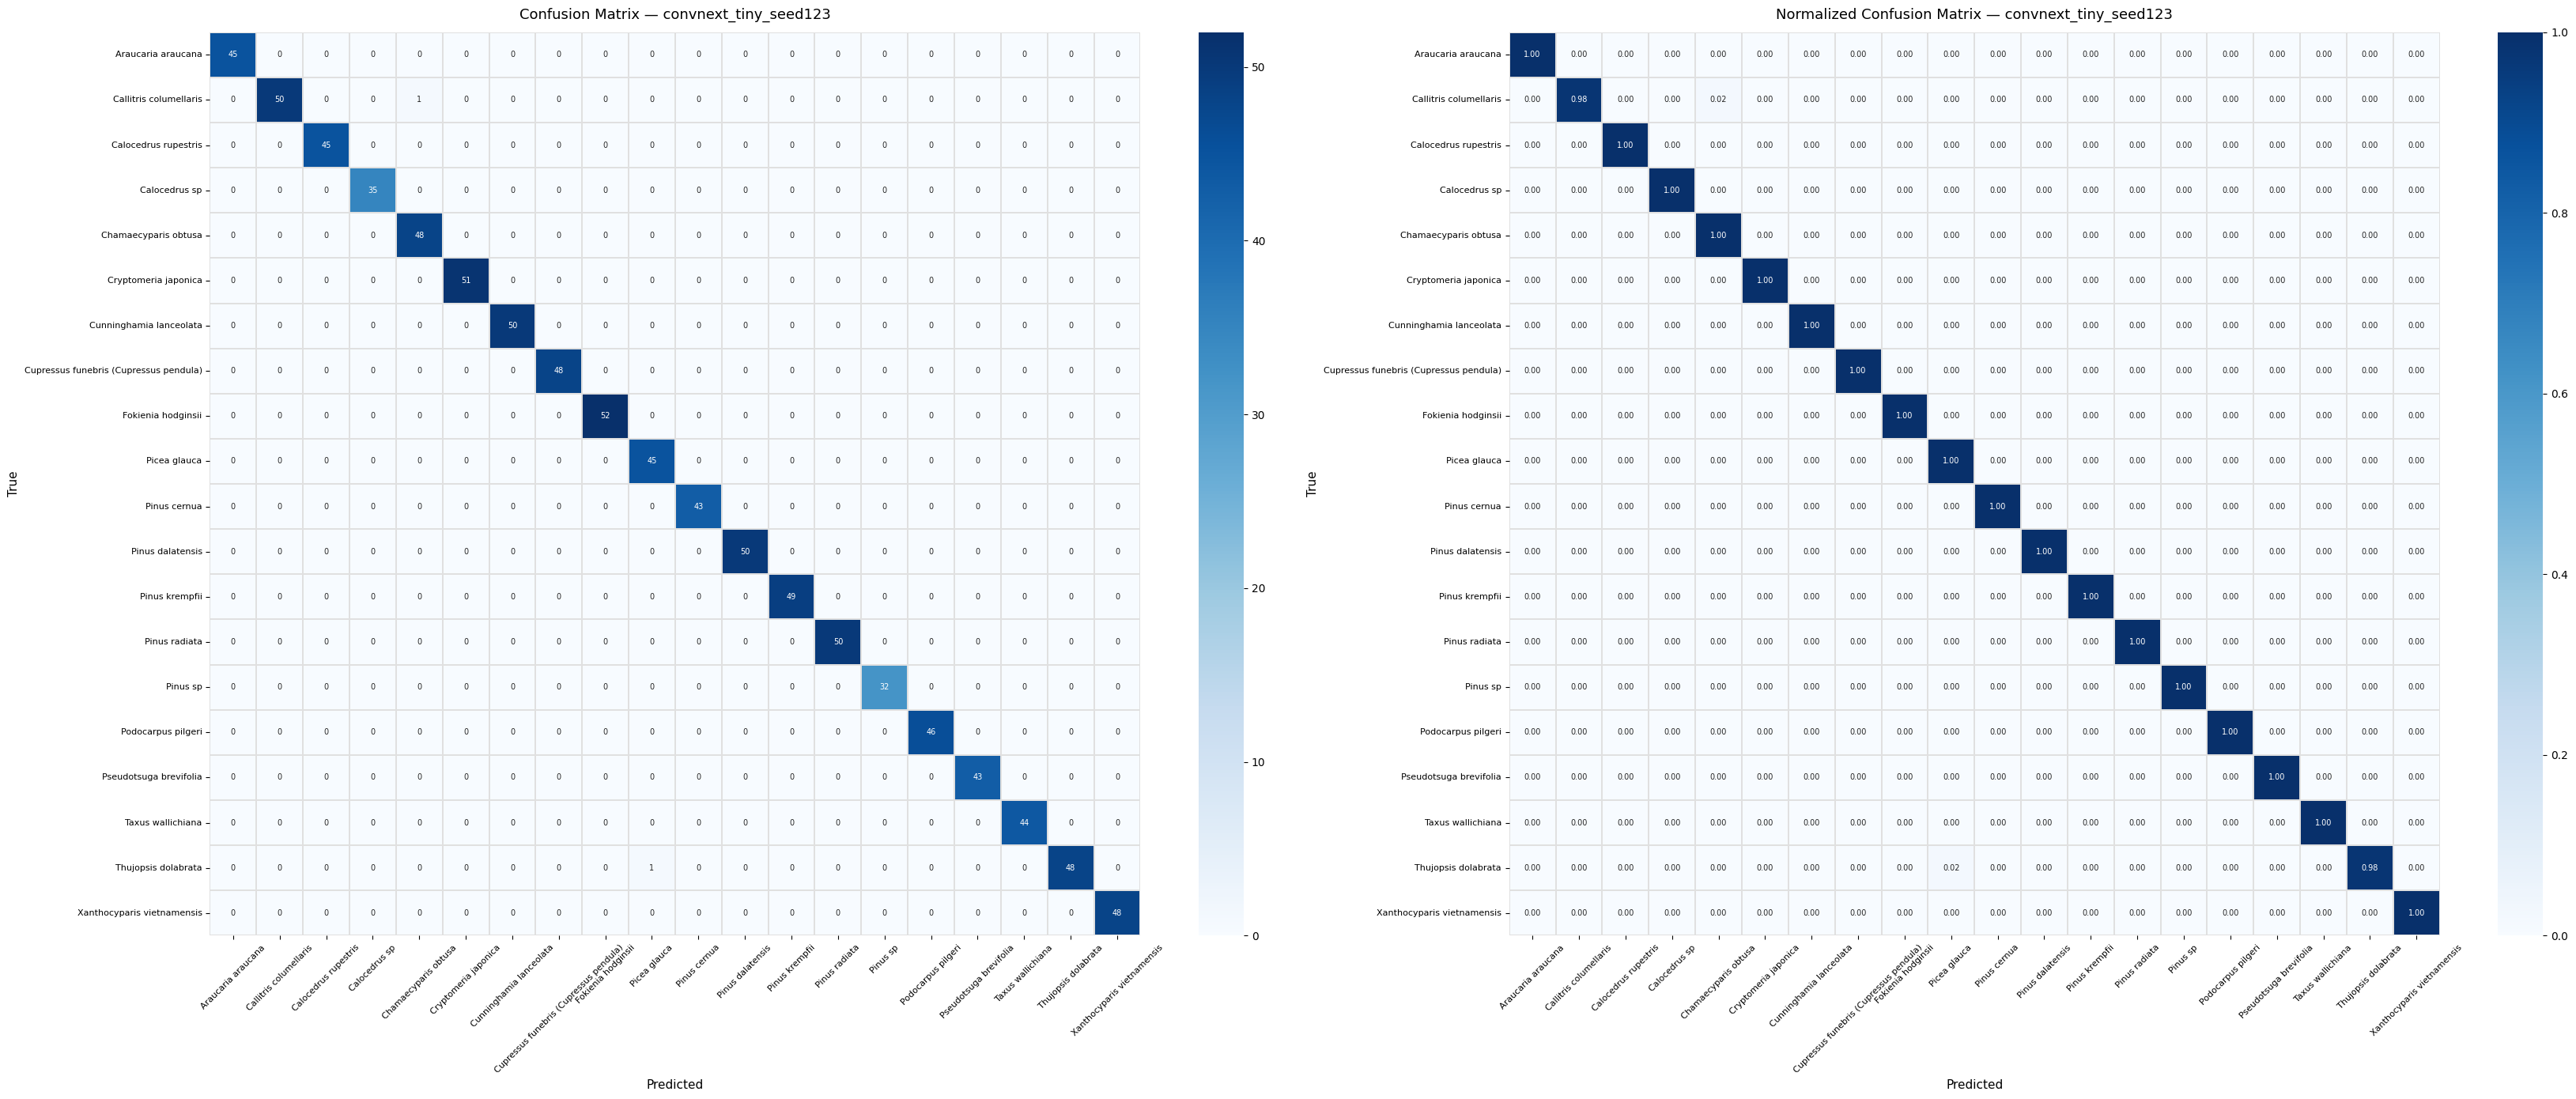

Đã lưu: /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/taskB/_evaluation/confusion_matrix_convnext_tiny_seed123.png


In [15]:
# ============================================================================
# Cell 12 — Confusion Matrix của Best Model
# ============================================================================

if not all_results:
    print('Không có kết quả.')
else:
    best_run   = max(all_results, key=lambda r: r['f1_macro'])
    best_metrics = best_run['_metrics']
    cm         = best_metrics['confusion_matrix']
    cm_norm    = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    short_names = [c.replace('_', ' ') for c in CLASS_NAMES]

    print(f"Best model: {best_run['run_id']}  F1={best_run['f1_macro']*100:.2f}%  Acc={best_run['accuracy']*100:.2f}%")

    fig, axes = plt.subplots(1, 2, figsize=(34, 14))
    for ax, mat, title, fmt in zip(
        axes,
        [cm, cm_norm],
        [f'Confusion Matrix — {best_run["run_id"]}',
         f'Normalized Confusion Matrix — {best_run["run_id"]}'],
        ['d', '.2f'],
    ):
        sns.heatmap(
            mat, annot=True, fmt=fmt, cmap='Blues',
            xticklabels=short_names, yticklabels=short_names,
            ax=ax, linewidths=0.3, linecolor='#e0e0e0',
            annot_kws={'size': 7},
        )
        ax.set_title(title, fontsize=13, pad=12)
        ax.set_xlabel('Predicted', fontsize=11)
        ax.set_ylabel('True', fontsize=11)
        ax.tick_params(axis='x', rotation=45, labelsize=8)
        ax.tick_params(axis='y', rotation=0, labelsize=8)

    plt.tight_layout()
    cm_path = OUTPUT_DIR / f'confusion_matrix_{best_run["run_id"]}.png'
    fig.savefig(cm_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Đã lưu: {cm_path}')

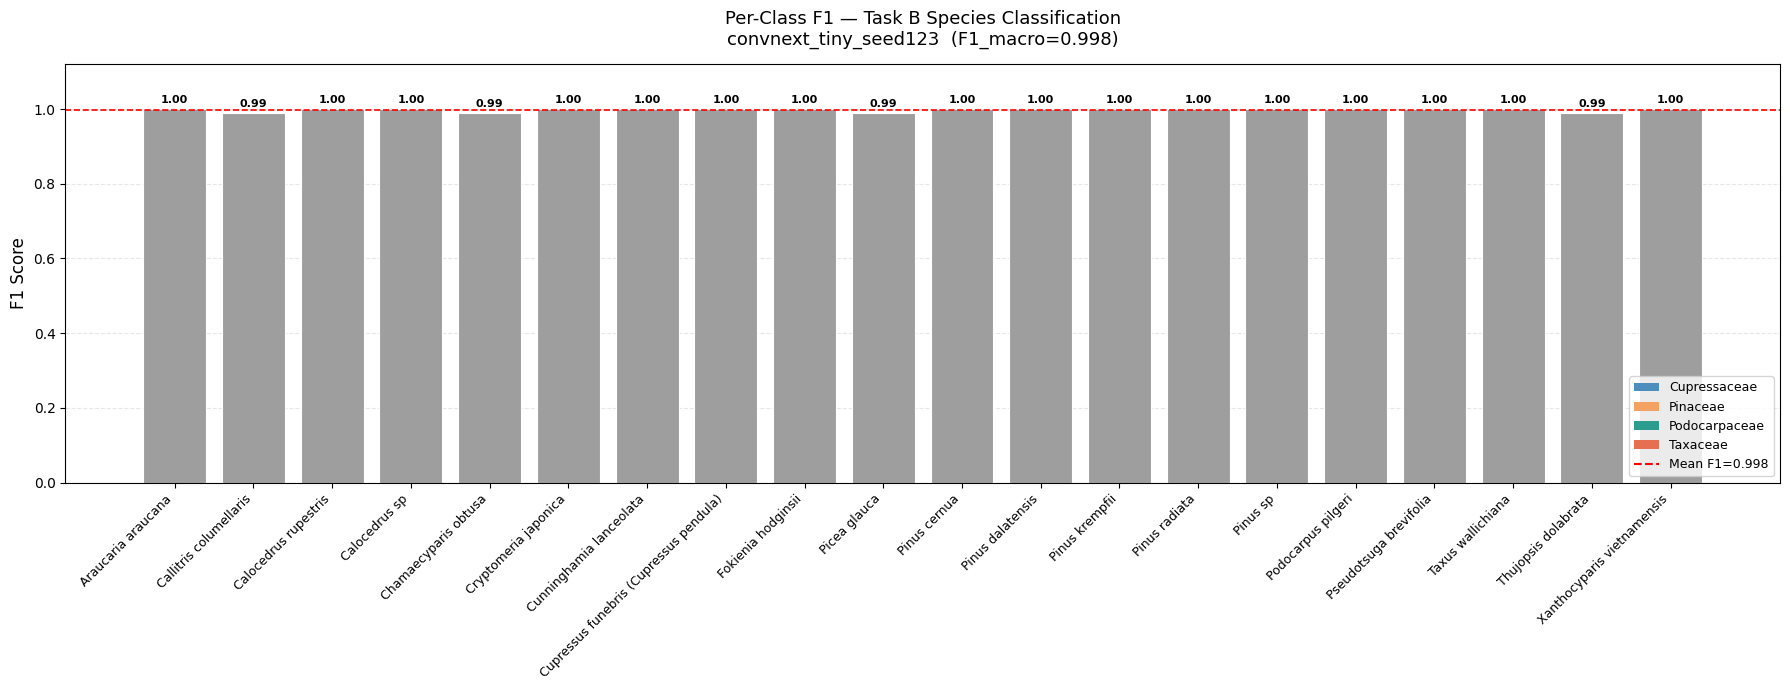

Đã lưu: /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/taskB/_evaluation/per_class_f1_convnext_tiny_seed123.png


In [16]:
# ============================================================================
# Cell 13 — Per-class F1 Bar Chart của Best Model
# ============================================================================

SPECIES_TO_FAMILY = {
    'Cunninghamia_lanceolata':    'Cupressaceae',
    'Callitris_columellaris':     'Cupressaceae',
    'Fokienia_hodginsii':         'Cupressaceae',
    'Cupressus_funebris':         'Cupressaceae',
    'Calocedrus_sp.':             'Cupressaceae',
    'Cryptomeria_japonica':       'Cupressaceae',
    'Xanthocyparis_vietnamensis': 'Cupressaceae',
    'Chamaecyparis_obtusa':       'Cupressaceae',
    'Calocedrus_rupestris':       'Cupressaceae',
    'Thujopsis_dolabrata':        'Cupressaceae',
    'Pinus_dalatensis':           'Pinaceae',
    'Pinus_radiata':              'Pinaceae',
    'Pinus_sp.':                  'Pinaceae',
    'Pinus_krempfii':             'Pinaceae',
    'Picea_luca':                 'Pinaceae',
    'Araucaria_araucana':         'Pinaceae',
    'Pseudotsuga_brevifolia':     'Pinaceae',
    'Pinus_cernua':               'Pinaceae',
    'Podocarpus_pilgeri':         'Podocarpaceae',
    'Taxus_wallichiana':          'Taxaceae',
}
FAMILY_COLORS = {
    'Cupressaceae':  '#4C8FBF',
    'Pinaceae':      '#F4A261',
    'Podocarpaceae': '#2A9D8F',
    'Taxaceae':      '#E76F51',
    'Unknown':       '#9E9E9E',
}

if not all_results:
    print('Không có kết quả.')
else:
    per_class  = best_run['_metrics']['per_class']
    f1_scores  = [per_class[cls]['f1'] for cls in CLASS_NAMES]
    colors     = [FAMILY_COLORS.get(SPECIES_TO_FAMILY.get(cls, 'Unknown'), '#9E9E9E') for cls in CLASS_NAMES]
    short_names = [c.replace('_', ' ') for c in CLASS_NAMES]
    mean_f1    = np.mean(f1_scores)

    fig, ax = plt.subplots(figsize=(18, 7))
    bars = ax.bar(range(len(f1_scores)), f1_scores, color=colors, edgecolor='white', linewidth=0.8)

    for bar, score in zip(bars, f1_scores):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{score:.2f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

    from matplotlib.patches import Patch
    legend_handles = [
        Patch(facecolor=c, label=f) for f, c in FAMILY_COLORS.items() if f != 'Unknown'
    ] + [plt.Line2D([0],[0], color='red', linestyle='--', label=f'Mean F1={mean_f1:.3f}')]
    ax.axhline(y=mean_f1, color='red', linestyle='--', linewidth=1.2)
    ax.legend(handles=legend_handles, loc='lower right', fontsize=9)

    ax.set_xticks(range(len(CLASS_NAMES)))
    ax.set_xticklabels(short_names, rotation=45, ha='right', fontsize=9)
    ax.set_ylabel('F1 Score', fontsize=12)
    ax.set_ylim(0, 1.12)
    ax.set_title(
        f'Per-Class F1 — Task B Species Classification\n{best_run["run_id"]}  (F1_macro={mean_f1:.3f})',
        fontsize=13, pad=14
    )
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    ax.set_axisbelow(True)

    plt.tight_layout()
    f1_path = OUTPUT_DIR / f'per_class_f1_{best_run["run_id"]}.png'
    fig.savefig(f1_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Đã lưu: {f1_path}')

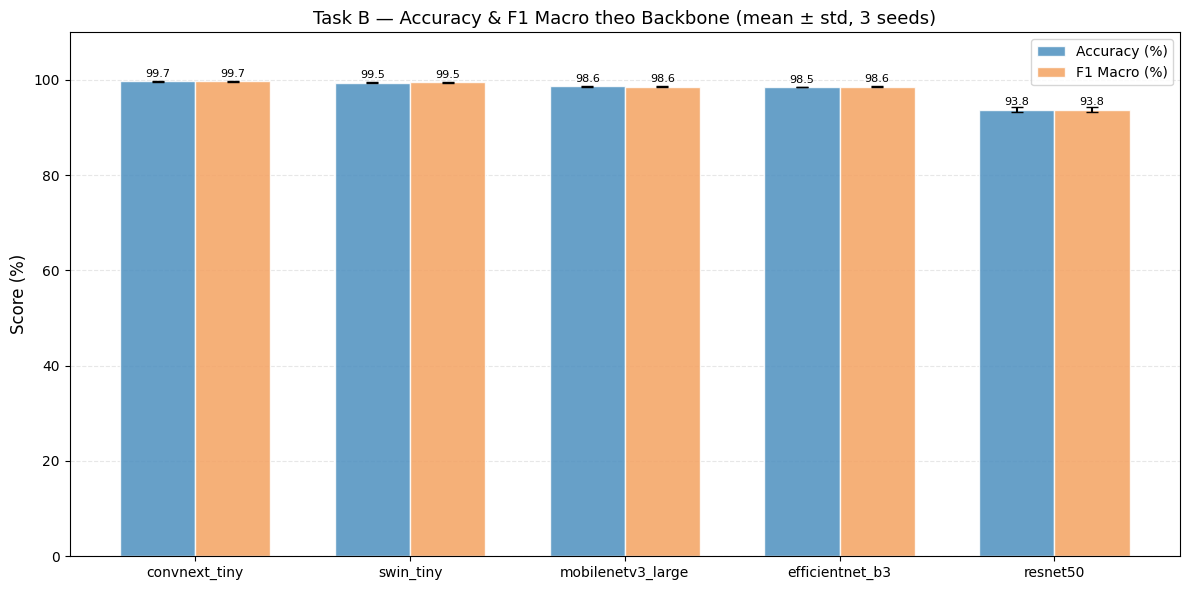

Đã lưu: /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/taskB/_evaluation/backbone_comparison.png


In [17]:
# ============================================================================
# Cell 14 — So sánh Backbone (Accuracy & F1 mean ± std)
# ============================================================================

if not all_results:
    print('Không có kết quả.')
else:
    df_plot = df.groupby('backbone')[['accuracy', 'f1_macro']].agg(['mean', 'std']).reset_index()
    df_plot.columns = ['backbone', 'acc_mean', 'acc_std', 'f1_mean', 'f1_std']
    df_plot = df_plot.sort_values('f1_mean', ascending=False)

    x = np.arange(len(df_plot))
    width = 0.35

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x - width/2, df_plot['acc_mean'] * 100, width,
           yerr=df_plot['acc_std'] * 100, capsize=4,
           label='Accuracy (%)', color='#4C8FBF', alpha=0.85, edgecolor='white')
    ax.bar(x + width/2, df_plot['f1_mean'] * 100, width,
           yerr=df_plot['f1_std'] * 100, capsize=4,
           label='F1 Macro (%)', color='#F4A261', alpha=0.85, edgecolor='white')

    for bar in ax.patches:
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.5,
                    f'{h:.1f}', ha='center', va='bottom', fontsize=8)

    ax.set_xticks(x)
    ax.set_xticklabels(df_plot['backbone'], fontsize=10)
    ax.set_ylabel('Score (%)', fontsize=12)
    ax.set_title('Task B — Accuracy & F1 Macro theo Backbone (mean ± std, 3 seeds)', fontsize=13)
    ax.legend(fontsize=10)
    ax.set_ylim(0, 110)
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    ax.set_axisbelow(True)

    plt.tight_layout()
    cmp_path = OUTPUT_DIR / 'backbone_comparison.png'
    fig.savefig(cmp_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Đã lưu: {cmp_path}')

In [18]:
# ============================================================================
# Cell 15 — Classification Report của Best Model (in + lưu file)
# ============================================================================

if not all_results:
    print('Không có kết quả.')
else:
    print(f"Nạp lại best model: {best_run['run_id']} để lấy predictions...")
    backbone  = best_run['backbone']
    ckpt_path = Path(best_run['checkpoint'])

    model, _, _ = load_model_from_checkpoint(ckpt_path, backbone, NUM_CLASSES, DEVICE)

    all_preds, all_labels = [], []
    model.eval()
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(DEVICE)
            preds  = model(images).argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    report = classification_report(
        all_labels, all_preds,
        target_names=CLASS_NAMES,
        zero_division=0, digits=4,
    )

    print(f"\nClassification Report — {best_run['run_id']}")
    print('=' * 72)
    print(report)

    report_path = OUTPUT_DIR / f'classification_report_{best_run["run_id"]}.txt'
    with open(report_path, 'w') as fp:
        fp.write(f"Classification Report — {best_run['run_id']}\n")
        fp.write('Train config: backbone={}, seeds=[42,123,456], epochs=50, bs=64/32,\n'.format(backbone))
        fp.write('              lr_head=1e-4, lr_backbone=1e-5, label_smoothing=0.1, cosine scheduler\n')
        fp.write('Dataset: ny0g507h3p/wood-task-B | Train=3973, Val=933, Test=924 | 20 classes\n')
        fp.write('=' * 72 + '\n')
        fp.write(report)
    print(f'\nĐã lưu: {report_path}')

    del model
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()

Nạp lại best model: convnext_tiny_seed123 để lấy predictions...

Classification Report — convnext_tiny_seed123
                                        precision    recall  f1-score   support

                    Araucaria araucana     1.0000    1.0000    1.0000        45
                Callitris columellaris     1.0000    0.9804    0.9901        51
                  Calocedrus rupestris     1.0000    1.0000    1.0000        45
                         Calocedrus sp     1.0000    1.0000    1.0000        35
                  Chamaecyparis obtusa     0.9796    1.0000    0.9897        48
                  Cryptomeria japonica     1.0000    1.0000    1.0000        51
               Cunninghamia lanceolata     1.0000    1.0000    1.0000        50
Cupressus funebris (Cupressus pendula)     1.0000    1.0000    1.0000        48
                    Fokienia hodginsii     1.0000    1.0000    1.0000        52
                          Picea glauca     0.9783    1.0000    0.9890        45
        

## Tóm tắt Đầu ra

| File | Nội dung |
|------|----------|
| `data/experiments/taskB/_evaluation/summary_results.csv` | Kết quả raw 15 runs |
| `data/experiments/taskB/_evaluation/summary_by_backbone.csv` | mean ± std theo backbone |
| `data/experiments/taskB/_evaluation/learning_curves_all_backbones.png` | Learning curves (từ notebook log) |
| `data/experiments/taskB/_evaluation/confusion_matrix_*.png` | Confusion matrix best model |
| `data/experiments/taskB/_evaluation/per_class_f1_*.png` | Per-class F1 bar chart |
| `data/experiments/taskB/_evaluation/backbone_comparison.png` | So sánh backbone |
| `data/experiments/taskB/_evaluation/classification_report_*.txt` | Full classification report |
| `data/experiments/taskB/<backbone>/seed_<N>/test_metrics.json` | Metrics per run |
| `data/experiments/taskB/<backbone>/seed_<N>/train_history.json` | Epoch-by-epoch train log |

---
**Bước tiếp theo:** Chạy Ablation Study Task 3.1 (90° Rotation):
```bash
conda activate wood
python train.py experiment=taskB_90rotation model.backbone=<best_backbone> train.seed=42 train.num_seeds=3
```